# BÀI 05 – PHÂN TÍCH THĂM DÒ DỮ LIỆU (EDA) GITHUB REPOSITORIES

**Mục tiêu:** Áp dụng bốn nhóm theo tài liệu Bài 05: Central tendency, Dispersion, Shape và Correlation; mở rộng kiểm định phù hợp cho câu hỏi về tuổi đời/ngôn ngữ và đối chiếu ba file chuẩn hóa.

**Cảnh báo nguồn:** Các tệp đã tải lên gồm một CSV raw và ba CSV biến đổi; không có file CSV “Folder 01 – đã điền khuyết”. Do đó notebook dùng raw làm nguồn EDA và không tuyên bố dữ liệu này đã impute. Missing values ở `description` và `license_key` được giữ nguyên; các biến số dùng cho phân tích đều đủ 12.000 quan sát.

## 1. Bảng phương pháp theo Bài 05

| Nhóm | Đại lượng / phương pháp | Vai trò trong dự án |
|---|---|---|
| Central tendency (Hướng trung tâm) | Mean, Median, Mode | Xác định vị trí trung tâm của Stars/Forks/Issues/Size |
| Dispersion (Độ phân tán) | Range, Quartile, IQR, Variance, Standard deviation, CV | Đo mức độ trải rộng và độ nhạy của range với ngoại lệ |
| Shape (Hình dáng) | Skewness, Kurtosis, Histogram, KDE, Boxplot | Nhận diện lệch, đuôi dài, ngoại lệ |
| Correlation (Tương quan) | Pearson, Spearman, Scatterplot, Heatmap | Đo liên hệ tuyến tính/đơn điệu, không phải quan hệ nhân quả |
| Gom nhóm | So sánh phân phối theo nhóm | Top 5 `primary_language` |
| ANOVA | F-test và p-value; kiểm định nhiều nhóm | Welch ANOVA bổ trợ, Kruskal–Wallis là kiểm định chính khi dữ liệu lệch mạnh |

## 2. Câu hỏi nghiên cứu

- **RQ1:** Những đặc điểm phân phối nào nổi bật ở Stars, Forks, Open Issues và Size?
- **RQ2:** Các ngôn ngữ lập trình có khác nhau về chỉ số `star_count` trong mẫu không?
- **RQ3:** Tuổi đời repository có liên hệ đơn điệu với Stars không?
- **RQ4:** Stars liên hệ với Forks, Open Issues, Size và số topic như thế nào?
- **RQ5:** Các file Scale, Z-Score và Min-Max đã biến đổi cột nào; dữ liệu có ghép cặp theo `repo_id` được không; phân phối/tương quan thay đổi ra sao?

Không đặt RQ về Watchers vì schema không có `watchers_count`.

In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "analysis_common.py").is_file() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "analysis_common.py").is_file():
    raise FileNotFoundError("Không tìm thấy analysis_common.py trong thư mục dự án.")
sys.path.insert(0, str(PROJECT_ROOT))

import json
import math
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown
from analysis_common import (
    load_raw_data, load_normalized_frames, prepare_analysis_frame,
    get_programming_language_frame, topic_frequency, save_figure,
    NUMERIC_METRICS, POPULARITY_METRICS, PROJECT_ROOT
)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

from itertools import combinations
from statsmodels.stats.multitest import multipletests

raw = load_raw_data()
df = prepare_analysis_frame(raw)
lang_df = get_programming_language_frame(df)
norm_frames = load_normalized_frames()
OUT = PROJECT_ROOT / "outputs" / "bai05"
OUT.mkdir(parents=True, exist_ok=True)
RESULTS = PROJECT_ROOT / "results"
RESULTS.mkdir(parents=True, exist_ok=True)
print(f"Raw shape: {raw.shape}; rows with duplicate repo_id: {raw['repo_id'].duplicated().sum()}")
print(f"Snapshot: {df['collected_at_dt'].min()}; Watchers field exists: {'watchers_count' in raw.columns}")

Raw shape: (12000, 21); rows with duplicate repo_id: 0
Snapshot: 2026-10-26 02:04:57+00:00; Watchers field exists: False


## 3. Kiểm tra chất lượng dữ liệu

Kiểm tra shape, schema, missing values, trùng lặp, giá trị âm và tính hợp lệ của ngày. Các cột `topics`/`languages` là chuỗi JSON nên được parse trong bộ nhớ, không sửa CSV nguồn.

In [2]:
missing_table = pd.DataFrame({
    "column": raw.columns,
    "dtype": raw.dtypes.astype(str).values,
    "missing_count": raw.isna().sum().values,
    "missing_pct": (raw.isna().mean().values * 100).round(3),
    "n_unique": [raw[c].nunique(dropna=True) for c in raw.columns],
})
missing_table.to_csv(RESULTS / "data_quality_by_column.csv", index=False, encoding="utf-8-sig")

invalid = {
    "duplicate_full_rows": int(raw.duplicated().sum()),
    "duplicate_repo_id": int(raw["repo_id"].duplicated().sum()),
    "negative_star_count": int((raw["star_count"] < 0).sum()),
    "negative_forks_count": int((raw["forks_count"] < 0).sum()),
    "negative_open_issues_count": int((raw["open_issues_count"] < 0).sum()),
    "negative_size_kb": int((raw["size_kb"] < 0).sum()),
    "description_missing": int(raw["description"].isna().sum()),
    "license_missing": int(raw["license_key"].isna().sum()),
    "updated_after_collected": int((df["updated_at_dt"] > df["collected_at_dt"]).sum()),
    "pushed_after_collected": int((df["pushed_at_dt"] > df["collected_at_dt"]).sum()),
    "pushed_before_created": int((df["pushed_at_dt"] < df["created_at_dt"]).sum()),
}
quality_summary = pd.DataFrame([{"check": k, "count": v} for k, v in invalid.items()])
quality_summary.to_csv(RESULTS / "data_quality_checks.csv", index=False, encoding="utf-8-sig")
display(missing_table.sort_values("missing_count", ascending=False).head(10))
display(quality_summary)
print("JSON parse failures - topics:", sum(not isinstance(x, list) for x in raw["topics"].map(lambda v: __import__('json').loads(v))))
print("Note: 1.043 updated_at và 225 pushed_at nằm sau collected_at; 3 pushed_at trước created_at. Cần xác minh logic thu thập.")

,column,dtype,missing_count,missing_pct,n_unique
9,license_key,object,1657,13.808,32
6,description,object,643,5.358,11340
2,repo_name,object,0,0.000,11708
1,owner,object,0,0.000,9130
0,repo_id,int64,0,0.000,12000
4,primary_language,object,0,0.000,104
3,full_name,object,0,0.000,12000
7,read_me,bool,0,0.000,2
5,languages,object,0,0.000,6368
8,topics,object,0,0.000,11772


,check,count
0,duplicate_full_rows,0
1,duplicate_repo_id,0
2,negative_star_count,0
3,negative_forks_count,0
4,negative_open_issues_count,0
5,negative_size_kb,0
6,description_missing,643
7,license_missing,1657
8,updated_after_collected,1043
9,pushed_after_collected,225


JSON parse failures - topics: 0
Note: 1.043 updated_at và 225 pushed_at nằm sau collected_at; 3 pushed_at trước created_at. Cần xác minh logic thu thập.


## 4. Thống kê mô tả – Central tendency, Dispersion và Shape

Bảng dưới đây tính trên giá trị gốc. Mode được báo cáo cho biến đếm; không diễn giải mode của tuổi đời liên tục như một giá trị đại diện quan trọng. `CV = std / mean × 100%` chỉ được diễn giải khi mean khác 0.

In [3]:
NUM_COLS = ["star_count", "forks_count", "open_issues_count", "size_kb", "age_days", "topic_count"]

def summarize_variable(series, mode_is_useful=True):
    s = pd.to_numeric(series, errors="coerce").dropna().astype(float)
    q1, q2, q3 = s.quantile([0.25, 0.50, 0.75]).tolist()
    mode_value = s.mode().iloc[0] if mode_is_useful and not s.mode().empty else np.nan
    mean_value = s.mean()
    return {
        "Count": int(s.count()), "Mean": mean_value, "Median": q2, "Mode": mode_value,
        "Std": s.std(ddof=1), "Variance": s.var(ddof=1), "Min": s.min(),
        "Q1": q1, "Q2": q2, "Q3": q3, "IQR": q3-q1, "Max": s.max(),
        "Range": s.max()-s.min(), "Skewness": s.skew(), "Kurtosis_excess": s.kurt(),
        "CV_pct": (s.std(ddof=1)/mean_value*100) if mean_value != 0 else np.nan,
    }

summary = pd.DataFrame({c: summarize_variable(df[c], mode_is_useful=(c != "age_days")) for c in NUM_COLS}).T
summary.index.name = "variable"
summary.to_csv(RESULTS / "descriptive_statistics.csv", encoding="utf-8-sig")
display(summary.style.format("{:,.4f}"))

,Count,Mean,Median,Mode,Std,Variance,Min,Q1,Q2,Q3,IQR,Max,Range,Skewness,Kurtosis_excess,CV_pct
variable,,,,,,,,,,,,,,,,
star_count,"12,000.0000","4,657.8088","1,713.0000",832.0000,"13,516.0417","182,683,383.3882",612.0000,"1,065.0000","1,713.0000","3,483.0000","2,418.0000","393,057.0000","392,445.0000",12.5814,236.8443,290.1803
forks_count,"12,000.0000",601.1798,174.0000,62.0000,"2,518.1652","6,341,155.9243",0.0000,88.0000,174.0000,392.0000,304.0000,"107,748.0000","107,748.0000",22.0246,715.9286,418.8706
open_issues_count,"12,000.0000",79.0252,18.0000,0.0000,596.5680,"355,893.3421",0.0000,5.0000,18.0000,53.0000,48.0000,"51,103.0000","51,103.0000",60.8331,"4,755.6885",754.9088
size_kb,"12,000.0000","109,556.9139","13,518.5000",29.0000,"889,179.7171","790,640,569,281.0391",0.0000,"2,165.7500","13,518.5000","58,916.2500","56,750.5000","57,192,250.0000","57,192,250.0000",38.9114,"1,971.0661",811.6144
age_days,"12,000.0000",573.8689,573.9356,nan,315.6279,"99,620.9890",25.3921,299.9185,573.9356,847.4632,547.5447,"1,120.8473","1,095.4552",0.0019,-1.2005,55.0000
topic_count,"12,000.0000",7.0392,4.0000,4.0000,5.0494,25.4963,0.0000,4.0000,4.0000,9.0000,5.0000,20.0000,20.0000,1.3104,0.6706,71.7327


### 4.1. Phân phối và ngoại lệ

Histogram/KDE nhận diện hình dáng, boxplot tóm tắt Q1–Median–Q3 và các điểm nằm ngoài whisker. Với các biến lệch mạnh, biểu đồ dùng `log1p` để dễ nhìn; mọi thước đo và phát hiện ngoại lệ IQR vẫn dựa trên giá trị gốc.

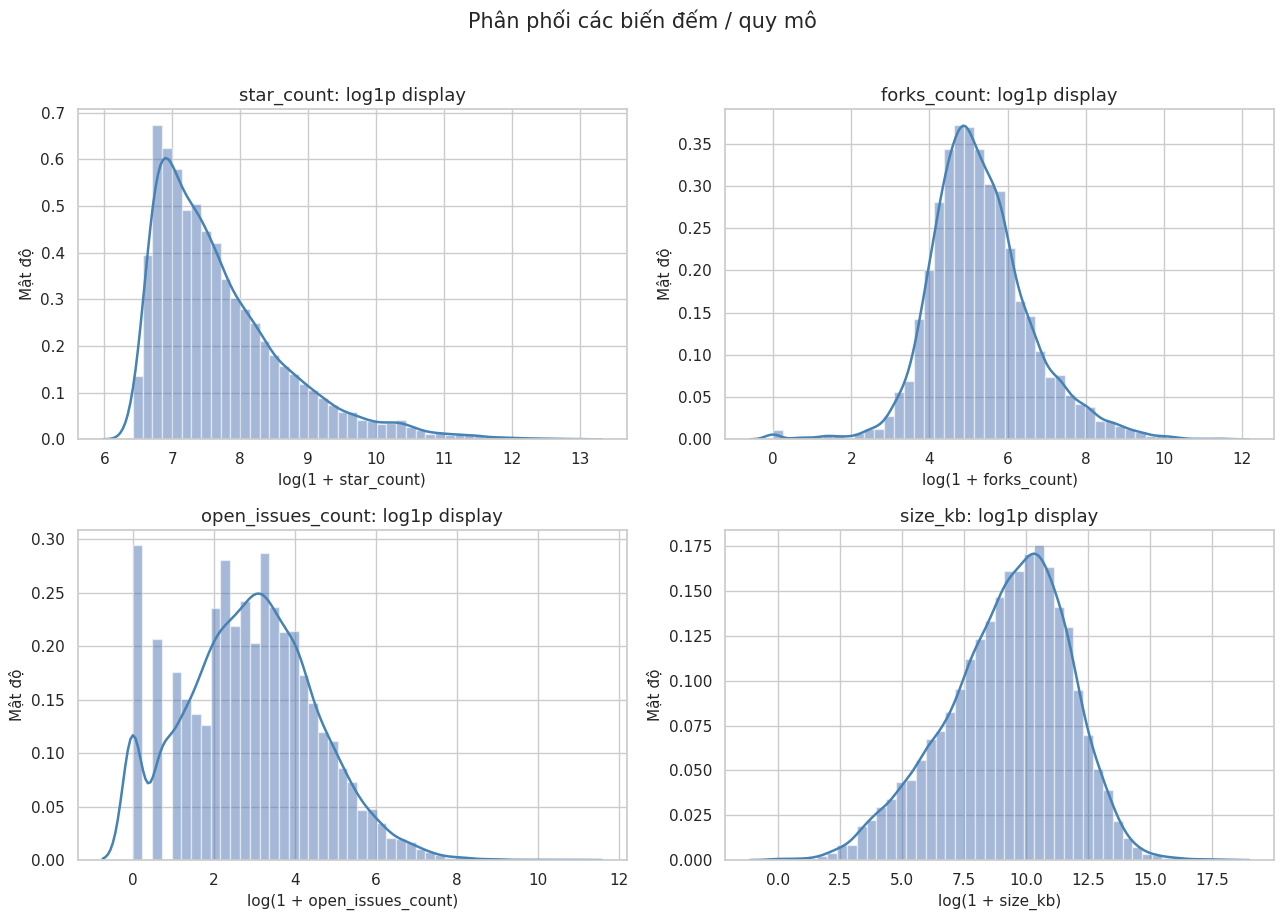

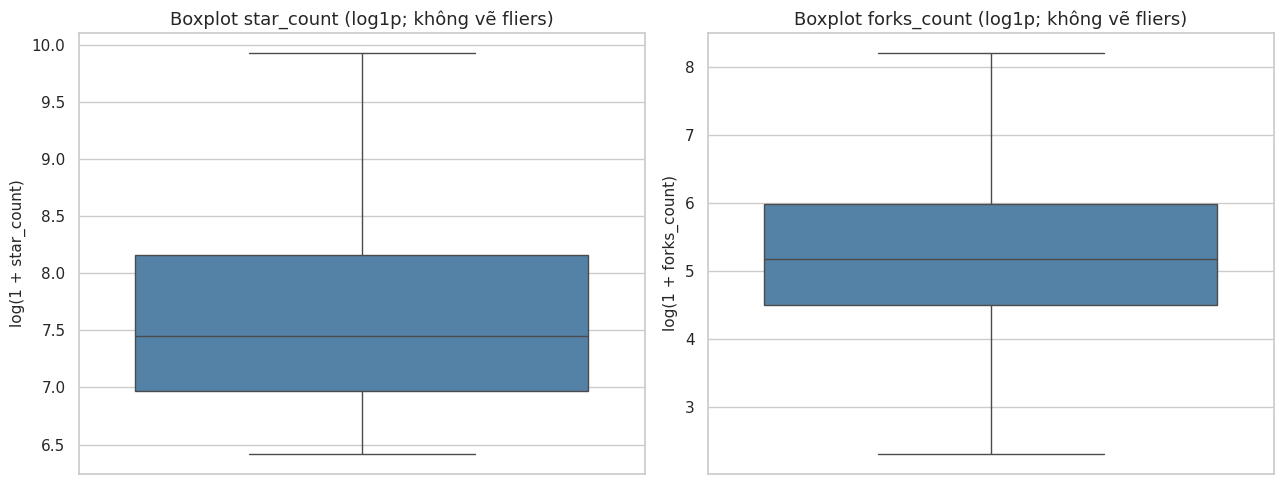

,variable,lower_fence,upper_fence,outlier_count,outlier_pct
0,star_count,"-2,562.00","7,110.00",1413,11.77%
1,forks_count,-368.00,848.00,1432,11.93%
2,open_issues_count,-67.00,125.00,1373,11.44%
3,size_kb,"-82,960.00","144,042.00",1509,12.57%


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col in zip(axes.flat, ["star_count", "forks_count", "open_issues_count", "size_kb"]):
    vals = np.log1p(df[col].astype(float))
    ax.hist(vals, bins=45, density=True, alpha=0.5, edgecolor="white")
    sns.kdeplot(x=vals, ax=ax, color="steelblue", linewidth=1.8)
    ax.set(title=f"{col}: log1p display", xlabel=f"log(1 + {col})", ylabel="Mật độ")
fig.suptitle("Phân phối các biến đếm / quy mô", y=1.02, fontsize=15)
fig.tight_layout()
save_figure(fig, OUT / "bai05_histogram_kde_numeric.png")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, col in zip(axes, ["star_count", "forks_count"]):
    sns.boxplot(y=np.log1p(df[col]), showfliers=False, color="steelblue", ax=ax)
    ax.set(title=f"Boxplot {col} (log1p; không vẽ fliers)", ylabel=f"log(1 + {col})")
fig.tight_layout()
save_figure(fig, OUT / "bai05_boxplot_popularity.png")
plt.show()

outlier_rows = []
for col in ["star_count", "forks_count", "open_issues_count", "size_kb"]:
    s = df[col]
    q1, q3 = s.quantile([.25,.75]); iqr = q3-q1
    lower, upper = q1-1.5*iqr, q3+1.5*iqr
    n_out = int(((s < lower) | (s > upper)).sum())
    outlier_rows.append({"variable":col,"lower_fence":lower,"upper_fence":upper,"outlier_count":n_out,"outlier_pct":n_out/len(s)*100})
outlier_table = pd.DataFrame(outlier_rows)
outlier_table.to_csv(RESULTS / "iqr_outlier_summary.csv", index=False, encoding="utf-8-sig")
display(outlier_table.style.format({"lower_fence":"{:,.2f}","upper_fence":"{:,.2f}","outlier_pct":"{:.2f}%"}))

**Diễn giải trọng tâm:** mean lớn hơn median cùng skewness dương lớn cho thấy đuôi phải kéo mean lên. Outlier theo quy tắc 1.5×IQR là điểm nằm ngoài hàng rào thống kê, không tự động là dữ liệu sai.

## 5. Phân tích ngôn ngữ lập trình

Dùng `primary_language` làm nhóm. Nhãn `text` (958 dòng) không được xem là ngôn ngữ lập trình, vì vậy loại khỏi mẫu số khi so sánh ngôn ngữ; vẫn giữ những dòng này cho phân tích số toàn bộ dataset.

,primary_language_clean,repository_count,median_stars,q1_stars,q3_stars,median_forks,q1_forks,q3_forks,share_pct_programming_language_sample
0,Python,3846,"1,706",1071.000000,3498.500000,191,98.000000,432.750000,34.83%
1,TypeScript,2319,"1,943",1162.500000,4204.500000,208,102.000000,451.500000,21.00%
2,JavaScript,747,"1,718",1062.000000,3245.500000,230,98.000000,535.000000,6.77%
3,Rust,710,"1,869",1110.250000,3957.750000,128,65.000000,281.500000,6.43%
4,Go,576,"1,744",1098.500000,3642.500000,156,82.000000,329.750000,5.22%
5,C++,313,"1,367",919.000000,2961.000000,151,79.000000,286.000000,2.83%
6,Jupyter Notebook,275,"1,766",1066.000000,4100.500000,273,127.000000,570.000000,2.49%
7,Shell,259,"1,527",962.000000,3219.000000,158,86.000000,392.500000,2.35%
8,Swift,242,"1,842",1096.500000,3209.000000,132,70.500000,261.500000,2.19%
9,HTML,241,"1,703",1040.000000,3675.000000,214,94.000000,423.000000,2.18%


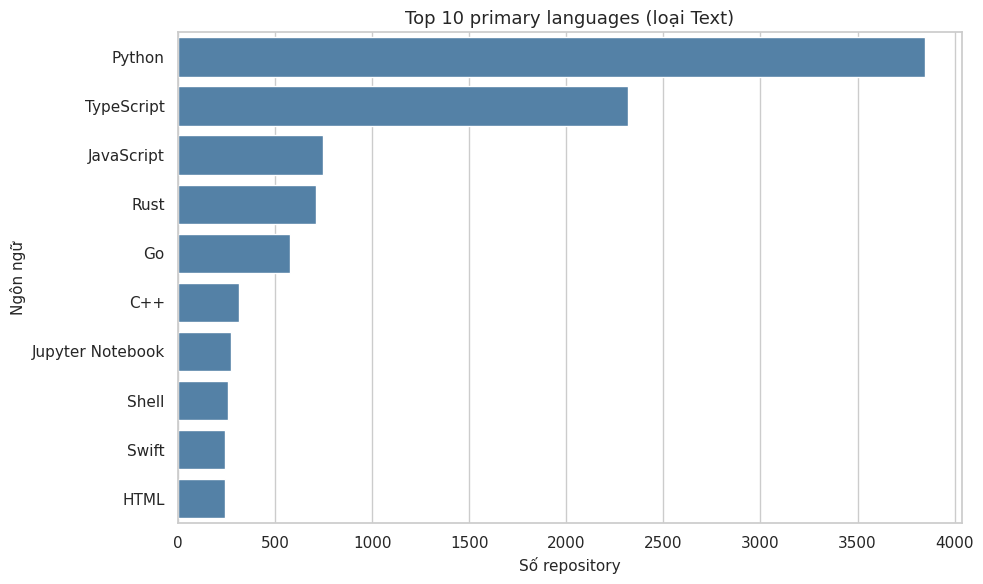

,primary_language_clean,repository_count,median_stars,q1_stars,q3_stars,median_forks,q1_forks,q3_forks,share_pct_programming_language_sample
0,Python,3846,1706.0,1071.00,3498.50,191.0,98.0,432.75,34.830647
1,TypeScript,2319,1943.0,1162.50,4204.50,208.0,102.0,451.50,21.001630
2,JavaScript,747,1718.0,1062.00,3245.50,230.0,98.0,535.00,6.765079
3,Rust,710,1869.0,1110.25,3957.75,128.5,65.0,281.50,6.429995
4,Go,576,1744.5,1098.50,3642.50,156.5,82.0,329.75,5.216446


In [5]:
lang_counts = lang_df["primary_language_clean"].value_counts()
top10 = lang_counts.head(10)
lang_summary = (
    lang_df.groupby("primary_language_clean")
    .agg(repository_count=("repo_id","size"), median_stars=("star_count","median"),
         q1_stars=("star_count",lambda s:s.quantile(.25)), q3_stars=("star_count",lambda s:s.quantile(.75)),
         median_forks=("forks_count","median"), q1_forks=("forks_count",lambda s:s.quantile(.25)),
         q3_forks=("forks_count",lambda s:s.quantile(.75)))
    .sort_values("repository_count",ascending=False)
    .reset_index()
)
lang_summary["share_pct_programming_language_sample"] = lang_summary["repository_count"] / len(lang_df) * 100
lang_summary.to_csv(RESULTS / "language_summary.csv", index=False, encoding="utf-8-sig")
display(lang_summary.head(10).style.format({"share_pct_programming_language_sample":"{:.2f}%","median_stars":"{:,.0f}","median_forks":"{:,.0f}"}))

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=top10.values, y=top10.index, orient="h", color="steelblue", ax=ax)
ax.set(title="Top 10 primary languages (loại Text)", xlabel="Số repository", ylabel="Ngôn ngữ")
fig.tight_layout()
save_figure(fig, OUT / "bai05_language_counts.png")
plt.show()

lang_top5 = lang_counts.head(5).index.tolist()
lang_top5_summary = lang_summary[lang_summary["primary_language_clean"].isin(lang_top5)].copy()
display(lang_top5_summary)

## 6. Phân tích tuổi đời repository

Tuổi được tính `age_days = collected_at - created_at`, dùng snapshot chung `2026-10-26 02:04:57 UTC`. Không dùng ngày hiện tại. Biến đổi sang năm bằng cách chia 365,25 ngày.

,n,mean_years,median_years,q1_years,q3_years,iqr_years,min_years,max_years,std_years
0,"12,000.000",1.571,1.571,0.821,2.320,1.499,0.070,3.069,0.864


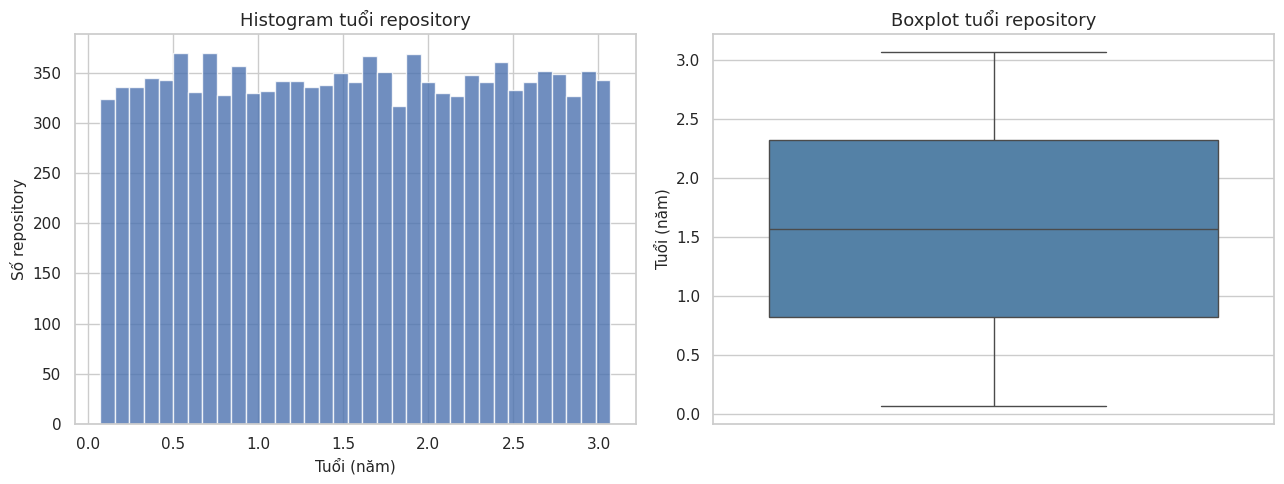

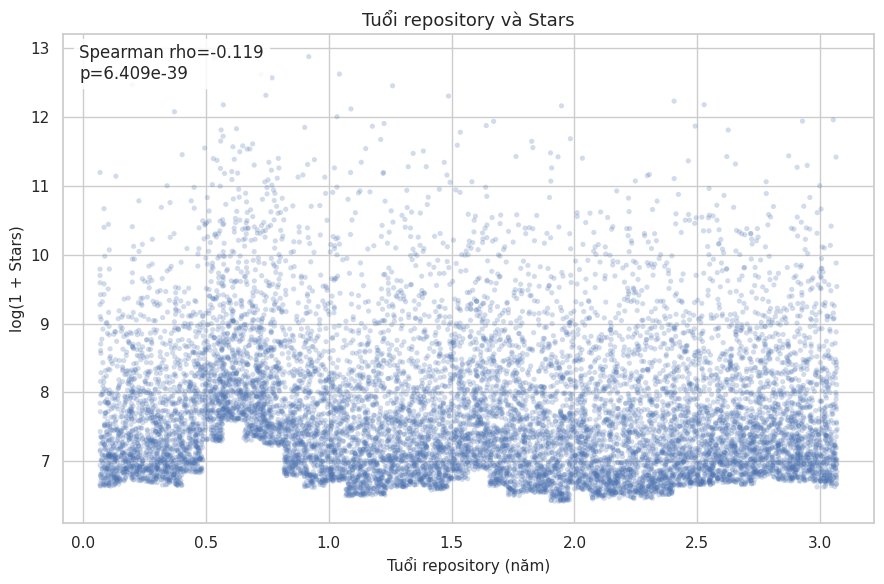

Spearman Age–Stars: rho=-0.1187; p=6.409e-39; n=12,000. Liên hệ âm yếu.


In [6]:
age_years = df["age_years"].dropna()
age_summary = pd.DataFrame([{
    "n":age_years.count(), "mean_years":age_years.mean(), "median_years":age_years.median(),
    "q1_years":age_years.quantile(.25), "q3_years":age_years.quantile(.75),
    "iqr_years":age_years.quantile(.75)-age_years.quantile(.25),
    "min_years":age_years.min(), "max_years":age_years.max(), "std_years":age_years.std()
}])
age_summary.to_csv(RESULTS / "repository_age_summary.csv", index=False, encoding="utf-8-sig")
display(age_summary.style.format("{:,.3f}"))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(age_years, bins=35, edgecolor="white", alpha=.8)
axes[0].set(title="Histogram tuổi repository", xlabel="Tuổi (năm)", ylabel="Số repository")
sns.boxplot(y=age_years, color="steelblue", ax=axes[1])
axes[1].set(title="Boxplot tuổi repository", ylabel="Tuổi (năm)")
fig.tight_layout()
save_figure(fig, OUT / "bai05_repository_age_distribution.png")
plt.show()

age_corr = stats.spearmanr(df["age_days"], df["star_count"])
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(df["age_years"], np.log1p(df["star_count"]), s=14, alpha=.25, edgecolors="none")
ax.set(title="Tuổi repository và Stars", xlabel="Tuổi repository (năm)", ylabel="log(1 + Stars)")
ax.text(.02,.98,f"Spearman rho={age_corr.statistic:.3f}\np={age_corr.pvalue:.3e}", transform=ax.transAxes, va="top", bbox={"facecolor":"white","alpha":.85})
fig.tight_layout()
save_figure(fig, OUT / "bai05_age_vs_stars.png")
plt.show()
print(f"Spearman Age–Stars: rho={age_corr.statistic:.4f}; p={age_corr.pvalue:.3e}; n={len(df):,}. Liên hệ âm yếu.")

## 7. Phân tích tương quan

Pearson đo liên hệ tuyến tính; Spearman đo liên hệ đơn điệu theo thứ hạng. Vì biến đếm có lệch và ngoại lệ, báo cáo cả hai; kết luận dựa vào chiều, độ lớn và ý nghĩa thực tiễn, không chỉ p-value.

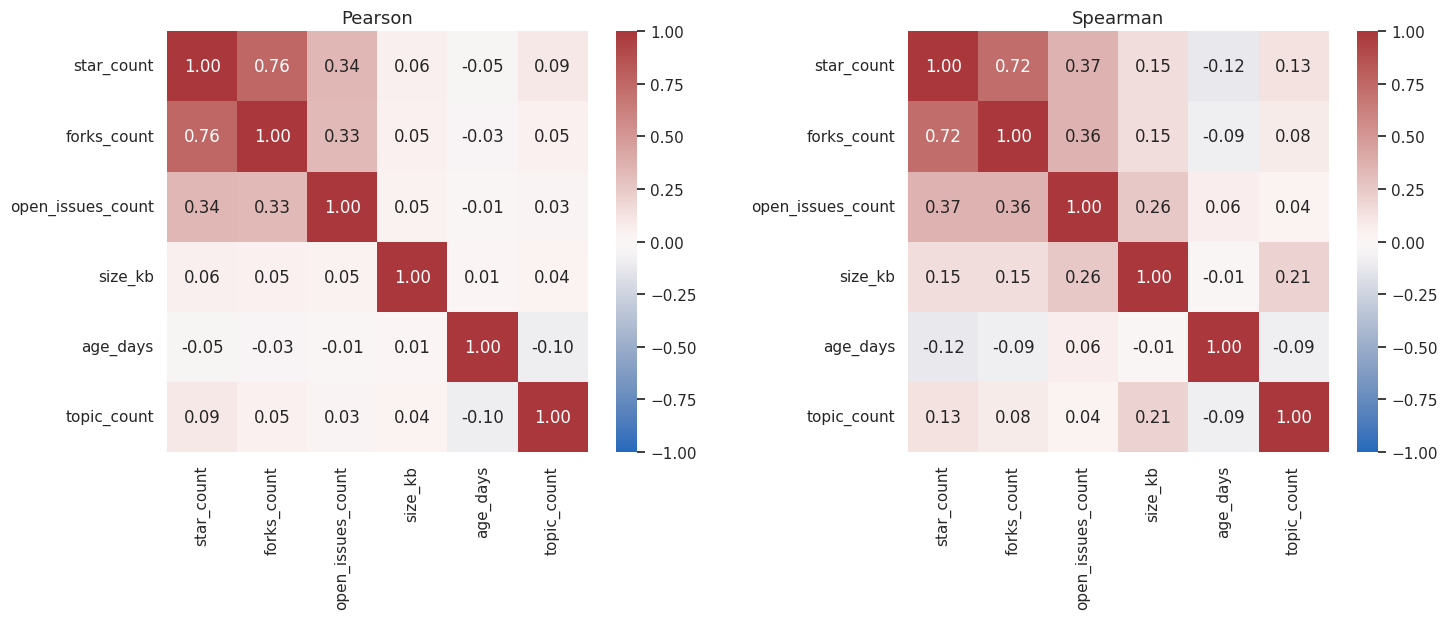

,x,y,pearson_r,pearson_p,spearman_rho,spearman_p,n
0,star_count,forks_count,0.7574,0.000e+00,0.7234,0.000e+00,12000
1,star_count,open_issues_count,0.3407,9.881e-324,0.3668,0.000e+00,12000
2,star_count,size_kb,0.0564,6.267e-10,0.1528,1.357e-63,12000
3,star_count,age_days,-0.0468,2.878e-07,-0.1187,6.409e-39,12000
4,star_count,topic_count,0.0939,6.757e-25,0.1256,2.013e-43,12000


In [7]:
CORR_COLS = ["star_count", "forks_count", "open_issues_count", "size_kb", "age_days", "topic_count"]
pearson_matrix = df[CORR_COLS].corr(method="pearson")
spearman_matrix = df[CORR_COLS].corr(method="spearman")
pearson_matrix.to_csv(RESULTS / "pearson_correlation_matrix.csv", encoding="utf-8-sig")
spearman_matrix.to_csv(RESULTS / "spearman_correlation_matrix.csv", encoding="utf-8-sig")
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(pearson_matrix, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=axes[0], square=True)
axes[0].set_title("Pearson")
sns.heatmap(spearman_matrix, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=axes[1], square=True)
axes[1].set_title("Spearman")
fig.tight_layout()
save_figure(fig, OUT / "bai05_correlation_heatmaps.png")
plt.show()

corr_rows = []
for other in ["forks_count", "open_issues_count", "size_kb", "age_days", "topic_count"]:
    p = stats.pearsonr(df["star_count"], df[other])
    s = stats.spearmanr(df["star_count"], df[other])
    corr_rows.append({"x":"star_count","y":other,"pearson_r":p.statistic,"pearson_p":p.pvalue,
                      "spearman_rho":s.statistic,"spearman_p":s.pvalue,"n":len(df)})
corr_pairs = pd.DataFrame(corr_rows)
corr_pairs.to_csv(RESULTS / "star_count_correlation_pairs.csv", index=False, encoding="utf-8-sig")
display(corr_pairs.style.format({"pearson_r":"{:.4f}","spearman_rho":"{:.4f}","pearson_p":"{:.3e}","spearman_p":"{:.3e}"}))

## 8. Kiểm định thống kê

### 8.1. RQ3 – Spearman giữa tuổi và Stars

- **H0:** Không có tương quan thứ hạng đơn điệu giữa `age_days` và `star_count` trong mẫu (rho = 0).
- **H1:** Có tương quan thứ hạng đơn điệu (rho ≠ 0).
- **Chọn kiểm định:** Spearman vì Stars và tuổi có thể không phân phối chuẩn, quan hệ cần xem theo thứ hạng.

### 8.2. RQ2 – Khác biệt Stars giữa Top 5 ngôn ngữ

- **H0:** Phân phối/thứ hạng `star_count` giống nhau giữa 5 nhóm ngôn ngữ.
- **H1:** Có ít nhất một nhóm khác biệt.
- **Kiểm định chính:** Kruskal–Wallis, phù hợp hơn khi phân phối lệch mạnh và ngoại lệ.
- **Kiểm tra bổ trợ:** Welch ANOVA để so sánh trung bình khi không giả định phương sai bằng nhau; đây không phải bằng chứng cho sự khác nhau về trung vị.
- Sau kiểm định tổng thể, so sánh cặp Mann–Whitney U và hiệu chỉnh Holm để hạn chế multiple testing.

In [8]:
alpha = 0.05
# Age vs Stars
age_test = stats.spearmanr(df["age_days"], df["star_count"])

# Top-5 programming language groups, each repository belongs to one primary-language group.
groups = [lang_df.loc[lang_df["primary_language_clean"] == name, "star_count"].dropna().to_numpy() for name in lang_top5]
kw = stats.kruskal(*groups)
try:
    welch = stats.f_oneway(*groups, equal_var=False)
    welch_name = "Welch ANOVA"
except TypeError:
    welch = stats.f_oneway(*groups)
    welch_name = "One-way ANOVA (SciPy không hỗ trợ equal_var=False)"
epsilon_sq = (kw.statistic - len(groups) + 1) / (sum(map(len, groups)) - len(groups))

test_rows = [
    {"question":"Age–Stars monotonic association","H0":"rho = 0","H1":"rho != 0","test":"Spearman correlation",
     "statistic":age_test.statistic,"p_value":age_test.pvalue,"alpha":alpha,
     "effect_size":"rho","effect_value":age_test.statistic,
     "conclusion":"Bác bỏ H0" if age_test.pvalue < alpha else "Chưa đủ bằng chứng bác bỏ H0"},
    {"question":"Stars distribution across Top 5 languages","H0":"Phân phối thứ hạng Stars giống nhau giữa 5 nhóm","H1":"Có ít nhất một nhóm khác biệt","test":"Kruskal-Wallis",
     "statistic":kw.statistic,"p_value":kw.pvalue,"alpha":alpha,
     "effect_size":"epsilon-squared","effect_value":epsilon_sq,
     "conclusion":"Bác bỏ H0" if kw.pvalue < alpha else "Chưa đủ bằng chứng bác bỏ H0"},
    {"question":"Mean Stars across Top 5 languages (sensitivity) ","H0":"Trung bình Stars bằng nhau","H1":"Có ít nhất một trung bình khác","test":welch_name,
     "statistic":welch.statistic,"p_value":welch.pvalue,"alpha":alpha,
     "effect_size":"F statistic (no eta-squared calculated)","effect_value":np.nan,
     "conclusion":"Bác bỏ H0" if welch.pvalue < alpha else "Chưa đủ bằng chứng bác bỏ H0"},
]
tests_df = pd.DataFrame(test_rows)
tests_df.to_csv(RESULTS / "statistical_tests.csv", index=False, encoding="utf-8-sig")
display(tests_df.style.format({"statistic":"{:.4f}","p_value":"{:.3e}","effect_value":"{:.4f}"}))

pair_rows = []
for a, b in combinations(lang_top5, 2):
    x = lang_df.loc[lang_df["primary_language_clean"] == a, "star_count"]
    y = lang_df.loc[lang_df["primary_language_clean"] == b, "star_count"]
    u, p = stats.mannwhitneyu(x, y, alternative="two-sided")
    pair_rows.append({"group_a":a,"group_b":b,"n_a":len(x),"n_b":len(y),"U":u,"p_raw":p})
if pair_rows:
    pair_df = pd.DataFrame(pair_rows)
    pair_df["p_holm"] = multipletests(pair_df["p_raw"], method="holm")[1]
    pair_df["significant_after_holm"] = pair_df["p_holm"] < alpha
    pair_df.to_csv(RESULTS / "language_pairwise_mannwhitney_holm.csv", index=False, encoding="utf-8-sig")
    display(pair_df.style.format({"U":"{:,.1f}","p_raw":"{:.3e}","p_holm":"{:.3e}"}))

,question,H0,H1,test,statistic,p_value,alpha,effect_size,effect_value,conclusion
0,Age–Stars monotonic association,rho = 0,rho != 0,Spearman correlation,-0.1187,6.409e-39,0.050000,rho,-0.1187,Bác bỏ H0
1,Stars distribution across Top 5 languages,Phân phối thứ hạng Stars giống nhau giữa 5 nhóm,Có ít nhất một nhóm khác biệt,Kruskal-Wallis,31.8041,2.098e-06,0.050000,epsilon-squared,0.0034,Bác bỏ H0
2,Mean Stars across Top 5 languages (sensitivity),Trung bình Stars bằng nhau,Có ít nhất một trung bình khác,Welch ANOVA,2.0703,8.223e-02,0.050000,F statistic (no eta-squared calculated),nan,Chưa đủ bằng chứng bác bỏ H0


,group_a,group_b,n_a,n_b,U,p_raw,p_holm,significant_after_holm
0,Python,TypeScript,3846,2319,"4,114,023.5",3.354e-07,3.354e-06,True
1,Python,JavaScript,3846,747,"1,447,557.5",7.384e-01,1.000e+00,False
2,Python,Rust,3846,710,"1,282,097.5",9.747e-03,7.797e-02,False
3,Python,Go,3846,576,"1,096,990.5",7.092e-01,1.000e+00,False
4,TypeScript,JavaScript,2319,747,"939,997.0",4.486e-04,4.037e-03,True
5,TypeScript,Rust,2319,710,"836,937.5",5.019e-01,1.000e+00,False
6,TypeScript,Go,2319,576,"713,359.5",1.129e-02,7.906e-02,False
7,JavaScript,Rust,747,710,"247,126.5",2.448e-02,1.469e-01,False
8,JavaScript,Go,747,576,"211,429.5",5.907e-01,1.000e+00,False
9,Rust,Go,710,576,"214,868.5",1.168e-01,5.838e-01,False


## 9. Đối chiếu ba file chuẩn hóa

Không có file Folder 01 đã impute. Vì vậy phần này dùng raw được cung cấp làm **mốc trước chuẩn hóa**; không đổi tên raw thành dữ liệu đã điền khuyết. Mỗi file chuẩn hóa được ghép cặp bằng `repo_id`, kiểm tra cả thứ tự và tập ID. Ba file không phải ba mẫu độc lập.

In [9]:
normalization_integrity = []
raw_ids = raw["repo_id"].reset_index(drop=True)
for method, ndf in norm_frames.items():
    ids = ndf["repo_id"].reset_index(drop=True)
    normalization_integrity.append({
        "file_method":method,"rows":len(ndf),"repo_id_unique":int(ndf["repo_id"].nunique()),
        "same_repo_id_set":set(raw["repo_id"]) == set(ndf["repo_id"]),
        "same_order":raw_ids.equals(ids),
        "extra_columns":"; ".join(sorted(set(ndf.columns)-set(raw.columns))),
    })
integrity_df = pd.DataFrame(normalization_integrity)
integrity_df.to_csv(RESULTS / "normalization_integrity.csv", index=False, encoding="utf-8-sig")
display(integrity_df)

scale_df = norm_frames.get("Scale")
zscore_df = norm_frames.get("Z-Score")
scale_equals_zscore = bool(scale_df is not None and zscore_df is not None and scale_df.equals(zscore_df))
print("Toàn bộ file Scale và Z-Score giống hệt nhau:", scale_equals_zscore)

# Which raw numerical columns changed? The candidate transformed fields are inferred only from exact paired comparisons.
changed_rows = []
for method, ndf in norm_frames.items():
    for col in raw.columns:
        if col not in ndf.columns:
            continue
        if pd.api.types.is_numeric_dtype(raw[col]) and pd.api.types.is_numeric_dtype(ndf[col]):
            same = np.allclose(pd.to_numeric(raw[col]), pd.to_numeric(ndf[col]), equal_nan=True)
        else:
            same = raw[col].astype("string").fillna("<NA>").equals(ndf[col].astype("string").fillna("<NA>"))
        changed_rows.append({"method":method,"column":col,"unchanged":bool(same)})
changed_df = pd.DataFrame(changed_rows)
changed_df.to_csv(RESULTS / "normalization_changed_columns.csv", index=False, encoding="utf-8-sig")
display(changed_df[changed_df["unchanged"] == False])

# Distribution summary for raw and each available transformed table.
norm_stats_rows = []
for method, frame in [("Raw", raw)] + list(norm_frames.items()):
    for col in NUMERIC_METRICS:
        s = pd.to_numeric(frame[col], errors="coerce").dropna()
        q1, q3 = s.quantile([.25,.75])
        norm_stats_rows.append({"dataset":method,"variable":col,"count":s.count(),"mean":s.mean(),"median":s.median(),
                                "std_sample":s.std(ddof=1),"min":s.min(),"q1":q1,"q3":q3,"iqr":q3-q1,
                                "max":s.max(),"skewness":s.skew()})
norm_stats = pd.DataFrame(norm_stats_rows)
norm_stats.to_csv(RESULTS / "normalization_descriptive_comparison.csv", index=False, encoding="utf-8-sig")
display(norm_stats[norm_stats["variable"] == "star_count"].style.format({c:"{:,.4f}" for c in norm_stats.select_dtypes(include="number").columns}))

,file_method,rows,repo_id_unique,same_repo_id_set,same_order,extra_columns
0,Scale,12000,12000,True,True,fork-bin; star-bin
1,Z-Score,12000,12000,True,True,fork-bin; star-bin
2,Min-Max,12000,12000,True,True,fork-bin; star-bin


Toàn bộ file Scale và Z-Score giống hệt nhau: True


,method,column,unchanged
14,Scale,star_count,False
15,Scale,forks_count,False
16,Scale,open_issues_count,False
17,Scale,size_kb,False
35,Z-Score,star_count,False
36,Z-Score,forks_count,False
37,Z-Score,open_issues_count,False
38,Z-Score,size_kb,False
56,Min-Max,star_count,False
57,Min-Max,forks_count,False


,dataset,variable,count,mean,median,std_sample,min,q1,q3,iqr,max,skewness
0,Raw,star_count,"12,000.0000","4,657.8088","1,713.0000","13,516.0417",612.0000,"1,065.0000","3,483.0000","2,418.0000","393,057.0000",12.5814
4,Scale,star_count,"12,000.0000",0.0000,-0.2179,1.0000,-0.2993,-0.2658,-0.0869,0.1789,28.7374,12.5814
8,Z-Score,star_count,"12,000.0000",0.0000,-0.2179,1.0000,-0.2993,-0.2658,-0.0869,0.1789,28.7374,12.5814
12,Min-Max,star_count,"12,000.0000",0.0103,0.0028,0.0344,0.0000,0.0012,0.0073,0.0062,1.0000,12.5814


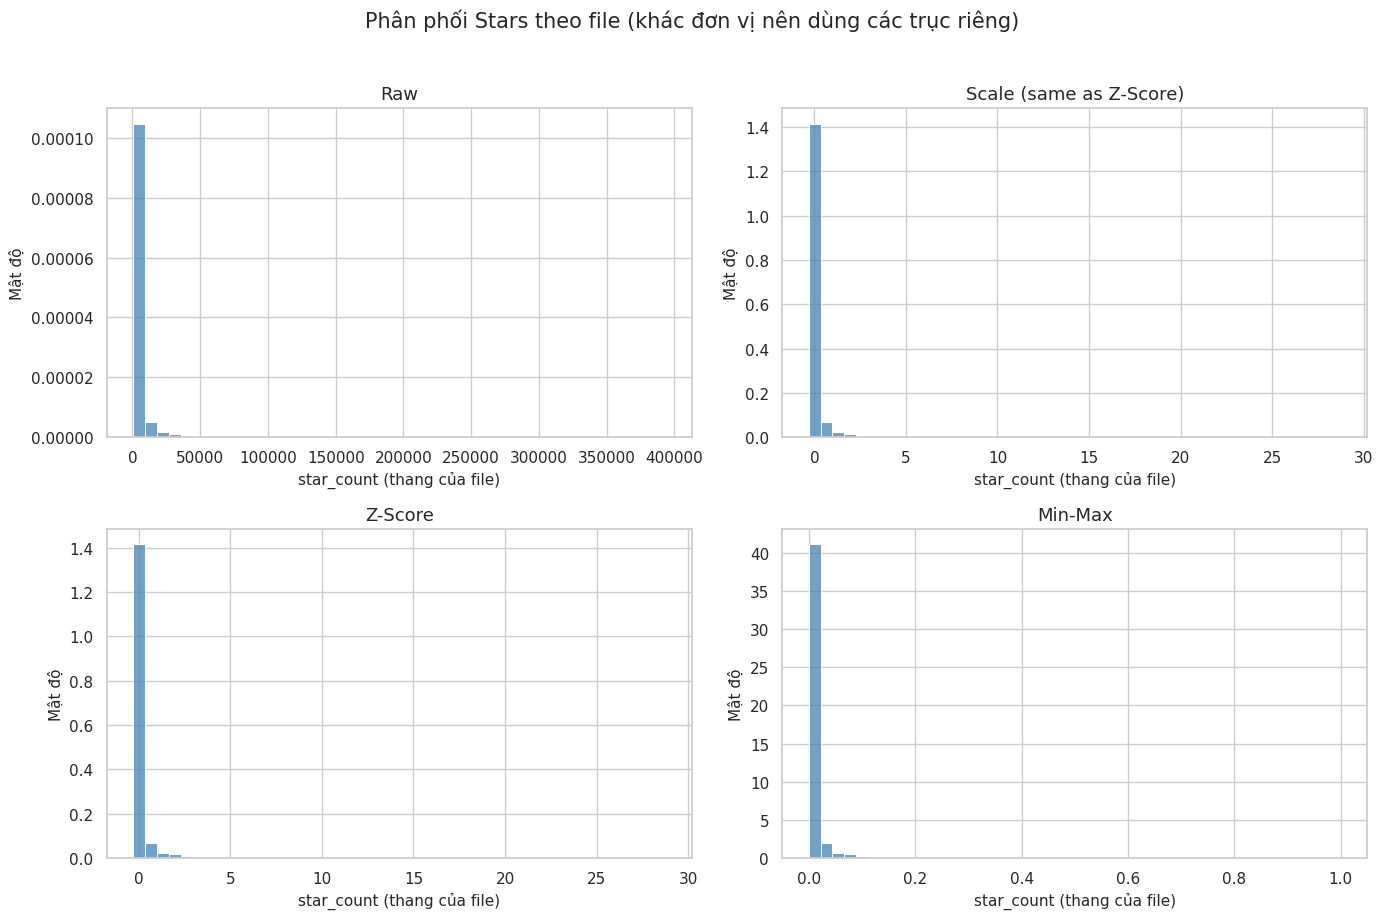

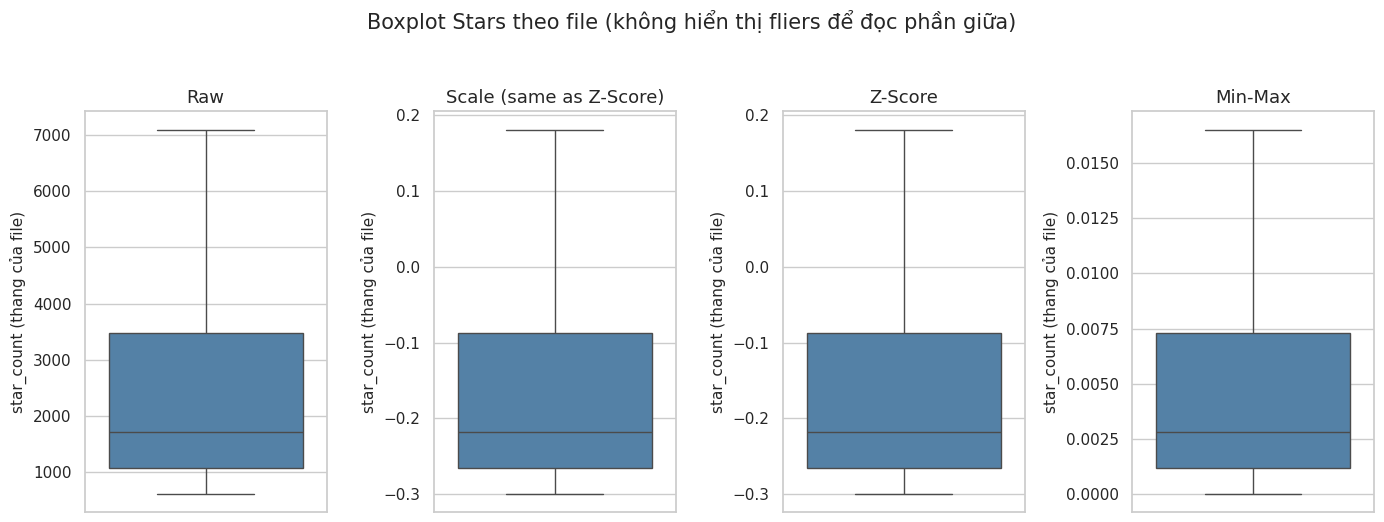

In [10]:
# Compare histogram/boxplot distributions on separate axes because the methods have different units.
frames_for_plot = [("Raw", raw), ("Scale (same as Z-Score)", norm_frames["Scale"]), ("Z-Score", norm_frames["Z-Score"]), ("Min-Max", norm_frames["Min-Max"])]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (name, frame) in zip(axes.flat, frames_for_plot):
    sns.histplot(x=frame["star_count"], bins=45, stat="density", kde=False, color="steelblue", ax=ax)
    ax.set(title=name, xlabel="star_count (thang của file)", ylabel="Mật độ")
fig.suptitle("Phân phối Stars theo file (khác đơn vị nên dùng các trục riêng)", y=1.02, fontsize=15)
fig.tight_layout()
save_figure(fig, OUT / "bai05_normalization_histogram_stars.png")
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(14, 5))
for ax, (name, frame) in zip(axes, frames_for_plot):
    sns.boxplot(y=frame["star_count"], showfliers=False, color="steelblue", ax=ax)
    ax.set(title=name, ylabel="star_count (thang của file)")
fig.suptitle("Boxplot Stars theo file (không hiển thị fliers để đọc phần giữa)", y=1.04, fontsize=15)
fig.tight_layout()
save_figure(fig, OUT / "bai05_normalization_boxplot_stars.png")
plt.show()

In [11]:
# Compare Pearson/Spearman relationships after transformation.
normal_corr_rows = []
for method, frame in [("Raw", raw)] + list(norm_frames.items()):
    p = stats.pearsonr(frame["star_count"], frame["forks_count"])
    s = stats.spearmanr(frame["star_count"], frame["forks_count"])
    normal_corr_rows.append({"dataset":method,"pearson_r":p.statistic,"spearman_rho":s.statistic})
normal_corr = pd.DataFrame(normal_corr_rows)
normal_corr.to_csv(RESULTS / "normalization_correlation_comparison.csv", index=False, encoding="utf-8-sig")
display(normal_corr.style.format({"pearson_r":"{:.10f}","spearman_rho":"{:.10f}"}))
print("Scale và Z-Score là cùng một file dữ liệu; không được xem như hai phương pháp khác nhau.")
print("Z-Score/Scale: trung bình gần 0, độ lệch chuẩn tổng thể gần 1. Min-Max: min=0, max=1.")
print("Các phép biến đổi tuyến tính dương bảo toàn thứ tự và tương quan; không suy ra phương pháp nào tốt hơn nếu chưa xác định mục tiêu downstream.")

,dataset,pearson_r,spearman_rho
0,Raw,0.7573669300,0.7234375314
1,Scale,0.7573669300,0.7234375314
2,Z-Score,0.7573669300,0.7234375314
3,Min-Max,0.7573669300,0.7234375314


Scale và Z-Score là cùng một file dữ liệu; không được xem như hai phương pháp khác nhau.
Z-Score/Scale: trung bình gần 0, độ lệch chuẩn tổng thể gần 1. Min-Max: min=0, max=1.
Các phép biến đổi tuyến tính dương bảo toàn thứ tự và tương quan; không suy ra phương pháp nào tốt hơn nếu chưa xác định mục tiêu downstream.


## 10. Tổng hợp phát hiện

1. **Phân phối lệch phải:** Stars, Forks, Open Issues và Size có mean lớn hơn median, skewness dương lớn; log1p là phép biến đổi phục vụ trực quan, không phải một trong ba file chuẩn hóa.
2. **Ngôn ngữ:** Top 5 được xác định theo số repo; Kruskal–Wallis kiểm tra thứ hạng Stars giữa nhóm. Kết quả thống kê phải đi cùng effect size, median và kích thước nhóm.
3. **Tuổi đời:** `age_days` được tính tại snapshot `collected_at`; Spearman kiểm tra liên hệ đơn điệu, không kết luận tuổi gây ra Stars.
4. **Tương quan:** Stars–Forks là cặp liên hệ nổi bật; Stars–Size/age/topic_count có độ lớn thấp hơn.
5. **Chuẩn hóa:** Scale và Z-Score trùng file; Min-Max khác. Không có file Folder 01 imputed; raw là mốc so sánh có sẵn. Không có cơ sở tuyên bố “tốt nhất” nếu chưa nêu mục tiêu mô hình hóa.

## 11. Giới hạn

- Mẫu chỉ có 12.000 repo và min Stars là 612; phương pháp lấy mẫu không được cung cấp nên không đại diện mặc nhiên toàn GitHub.
- Không có `watchers_count`, số người đóng góp, số commit hay lịch sử Stars theo thời gian.
- 643 description và 1.657 license_key bị thiếu; dữ liệu thiếu được giữ nguyên.
- 1.043 `updated_at` và 225 `pushed_at` sau `collected_at`; 3 `pushed_at` trước `created_at`; cần xác minh pipeline crawl.
- Hai file Scale/Z-Score giống hệt nhau nên chỉ có hai biến đổi thực sự trong ba tên file.
- Kết quả kiểm định trên mẫu lớn có thể có p-value nhỏ dù effect size nhỏ; không diễn giải p-value như mức độ quan trọng thực tiễn.